# CAN-ML Preprocessing Pipeline Visualization

This notebook walks through each step of the CAN bus data preprocessing pipeline,
from raw CSV to the final tensor format ready for ModernTCN classification.

**Pipeline overview:**
1. Raw CSV → Parse columns
2. Hex payload → 8 numeric bytes
3. Engineer temporal features (delta_t, id_freq)
4. Normalize all features to [0, 1]
5. Sliding window → (N, T, C) tensors
6. Label assignment per window
7. Stratified train/val/test split

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append('../')
print(sys.path[-3:])

['', '/home/hieutt/miniconda3/envs/torchtf/lib/python3.9/site-packages', '../']


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

# === CHANGE THIS to your data path ===
DATA_DIR = Path('../data/2017-subaru-forester/merged')
csv_files = sorted(DATA_DIR.glob('*.csv'))
print(f'Found {len(csv_files)} CSV files:')
for f in csv_files:
    print(f'  {f.name}')

Found 9 CSV files:
  combined.csv
  dos.csv
  fuzzing.csv
  gear.csv
  interval.csv
  rpm.csv
  speed.csv
  standstill.csv
  systematic.csv


## Step 1: Raw CAN Bus Data

Each CSV file represents one attack type. Columns:
- `timestamp`: when the CAN frame was captured
- `arbitration_id`: the ECU address (who is talking)
- `data_field`: payload in hex (what was said)
- `attack`: 0 = normal, 1 = attack frame

In [4]:
# Load one file as example
sample_file = csv_files[0]
df_raw = pd.read_csv(sample_file)

print(f'File: {sample_file.name}')
print(f'Shape: {df_raw.shape}')
print(f'Columns: {list(df_raw.columns)}')
print(f'\nFirst 10 rows (raw):')
df_raw.head(10)

File: combined.csv
Shape: (5806825, 4)
Columns: ['timestamp', 'arbitration_id', 'data_field', 'attack']

First 10 rows (raw):


,timestamp,arbitration_id,data_field,attack
0,1.672531e+09,164,0200000000000002,0
1,1.672531e+09,149,160c3f1fa9150000,0
2,1.672531e+09,140,000371082b2b3720,0
3,1.672531e+09,140,0001240828282720,0
4,1.672531e+09,604,a400000000000000,0
5,1.672531e+09,164,0200000000000002,0
6,1.672531e+09,149,160c3f1fa9150000,0
7,1.672531e+09,604,a400000000000000,0
8,1.672531e+09,371,000000c0fe1fff20,0
9,1.672531e+09,141,e32a3f2b24880002,0


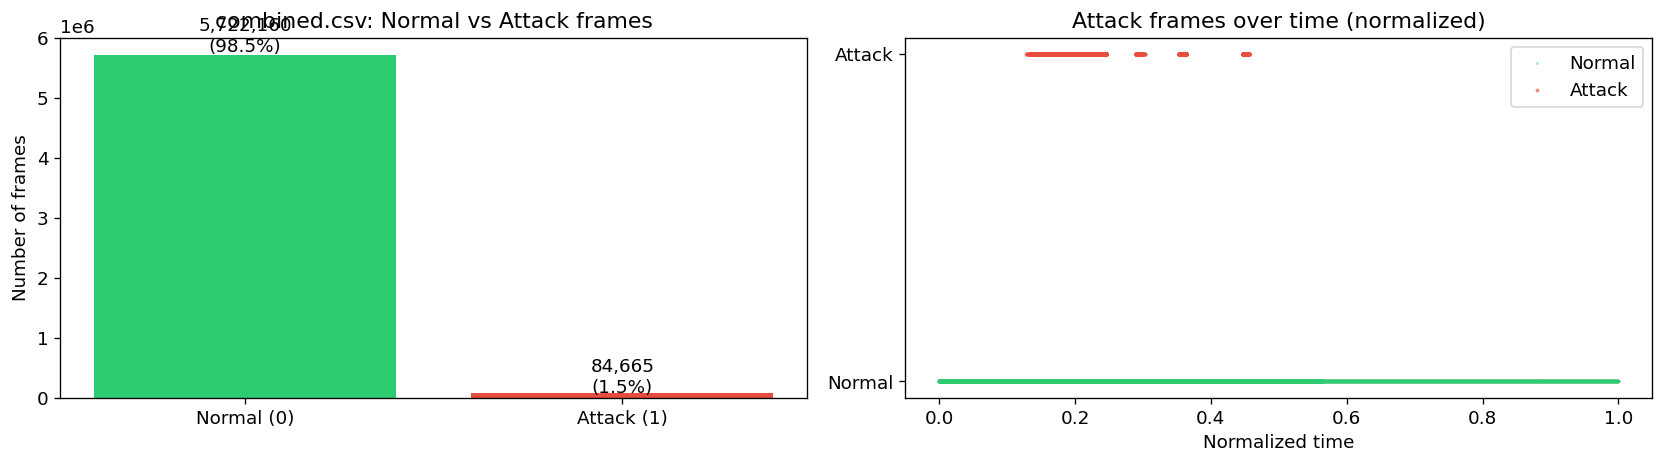

In [5]:
# Visualize attack distribution in raw data
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Attack ratio
atk_counts = df_raw['attack'].value_counts().sort_index()
colors = ['#2ecc71', '#e74c3c']
axes[0].bar(['Normal (0)', 'Attack (1)'], atk_counts.values, color=colors)
axes[0].set_title(f'{sample_file.name}: Normal vs Attack frames')
axes[0].set_ylabel('Number of frames')
for i, v in enumerate(atk_counts.values):
    axes[0].text(i, v + v*0.01, f'{v:,}\n({100*v/len(df_raw):.1f}%)', ha='center')

# Attack over time
ts = pd.to_numeric(df_raw['timestamp'], errors='coerce')
ts_norm = (ts - ts.min()) / (ts.max() - ts.min())
atk = df_raw['attack'].values
axes[1].scatter(ts_norm[atk==0].iloc[::100], atk[atk==0][::100],
                alpha=0.3, s=1, c='#2ecc71', label='Normal')
axes[1].scatter(ts_norm[atk==1].iloc[::10], atk[atk==1][::10],
                alpha=0.5, s=2, c='#e74c3c', label='Attack')
axes[1].set_title('Attack frames over time (normalized)')
axes[1].set_xlabel('Normalized time')
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(['Normal', 'Attack'])
axes[1].legend()

plt.tight_layout()
plt.show()

## Step 2: Hex Payload Parsing

The `data_field` column contains hex strings like `0200000000000002`.
We split this into 8 individual bytes (0-255 each).

**Example:** `0200000000000002` → `[02, 00, 00, 00, 00, 00, 00, 02]`

In [6]:
def safe_hex_to_bytes(hex_str, max_len=8):
    if pd.isna(hex_str):
        return np.zeros(max_len, dtype=np.float32), 0
    s = str(hex_str).strip().lower().replace(' ', '')
    if s.startswith('0x'):
        s = s[2:]
    if len(s) % 2 == 1:
        s = '0' + s
    s = s[:max_len * 2]
    vals = []
    for i in range(0, len(s), 2):
        try:
            vals.append(int(s[i:i+2], 16))
        except ValueError:
            vals.append(0)
    dlc = len(vals)
    vals.extend([0] * (max_len - dlc))
    return np.array(vals, dtype=np.float32), dlc

# Show examples
print('Hex payload parsing examples:')
print('=' * 70)
for i in range(5):
    raw = df_raw['data_field'].iloc[i]
    parsed, dlc = safe_hex_to_bytes(raw)
    print(f'  Raw: {str(raw):>20s}  →  Bytes: {parsed.astype(int).tolist()}  (DLC={dlc})')

Hex payload parsing examples:
  Raw:     0200000000000002  →  Bytes: [2, 0, 0, 0, 0, 0, 0, 2]  (DLC=8)
  Raw:     160c3f1fa9150000  →  Bytes: [22, 12, 63, 31, 169, 21, 0, 0]  (DLC=8)
  Raw:     000371082b2b3720  →  Bytes: [0, 3, 113, 8, 43, 43, 55, 32]  (DLC=8)
  Raw:     0001240828282720  →  Bytes: [0, 1, 36, 8, 40, 40, 39, 32]  (DLC=8)
  Raw:     a400000000000000  →  Bytes: [164, 0, 0, 0, 0, 0, 0, 0]  (DLC=8)


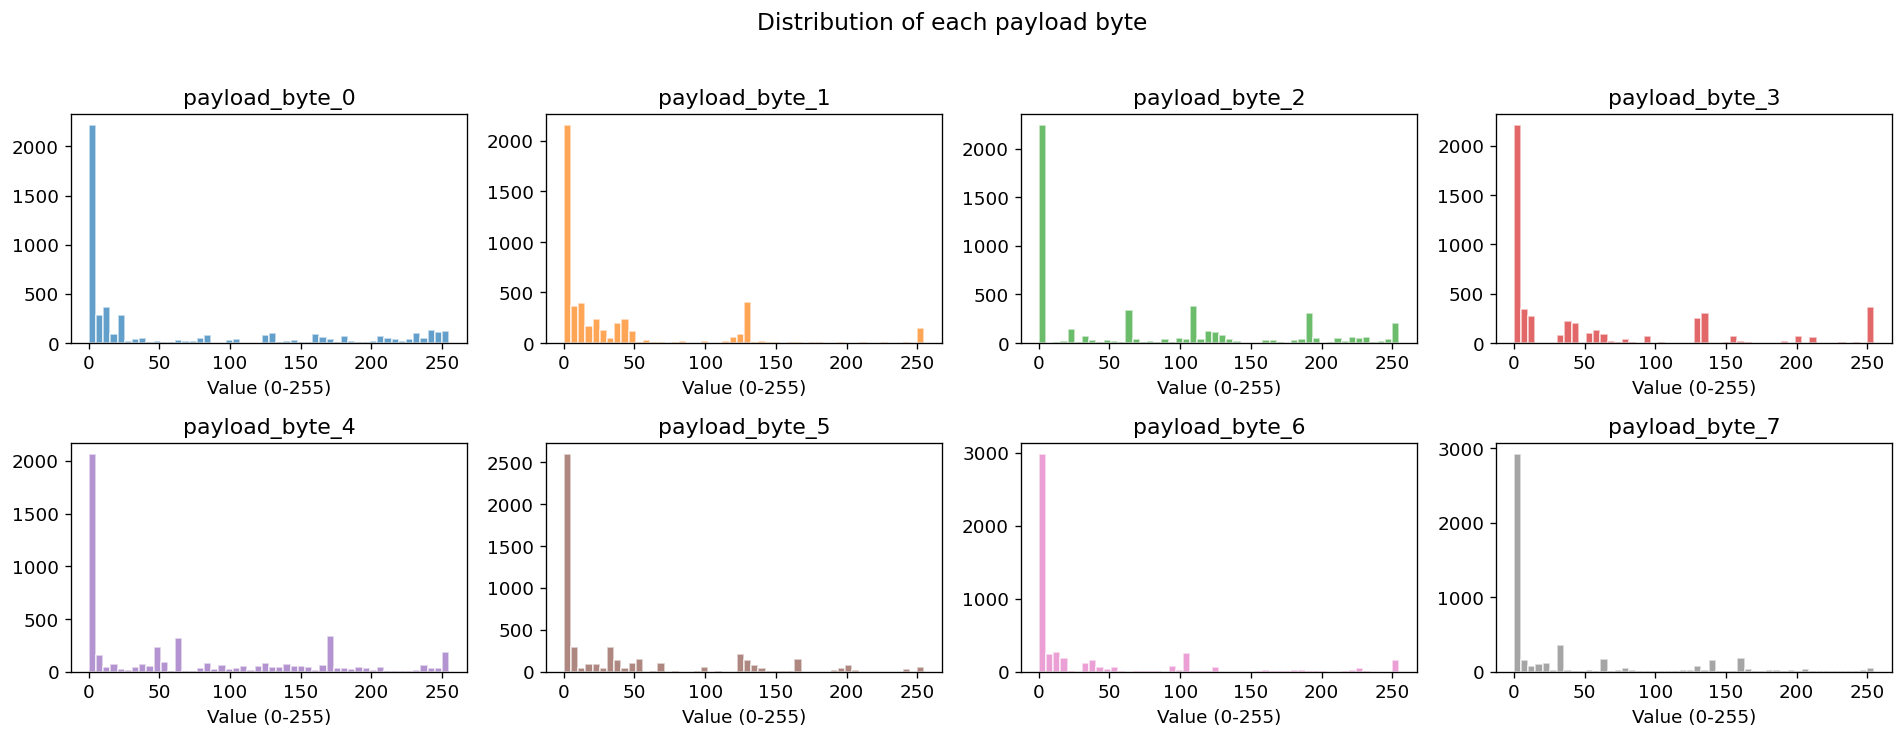

In [7]:
# Parse all payloads and visualize byte distributions
N_SHOW = min(5000, len(df_raw))
payload_arr = np.zeros((N_SHOW, 8), dtype=np.float32)
for i in range(N_SHOW):
    payload_arr[i], _ = safe_hex_to_bytes(df_raw['data_field'].iloc[i])

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, ax in enumerate(axes.flat):
    ax.hist(payload_arr[:, j], bins=50, color=f'C{j}', alpha=0.7, edgecolor='white')
    ax.set_title(f'payload_byte_{j}')
    ax.set_xlabel('Value (0-255)')
plt.suptitle('Distribution of each payload byte', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Step 3: Feature Engineering

From raw 4 columns, we engineer **12 features** per frame:

| # | Feature | Source | Meaning |
|---|---------|--------|---------|
| 0 | arbitration_id | direct | Which ECU is talking |
| 1 | dlc | from hex length | Data length code |
| 2-9 | payload_0..7 | hex parsing | 8 data bytes |
| 10 | log_delta_t | timestamp diff | Time gap between frames |
| 11 | id_freq_recent | sliding window count | How often this ID appeared recently |

In [8]:
from collections import deque

# Feature engineering on sample data
df = df_raw.copy()
df = df.sort_values('timestamp', kind='mergesort').reset_index(drop=True)
df['arbitration_id'] = pd.to_numeric(df['arbitration_id'], errors='coerce').fillna(0).astype(np.int64)
df['attack'] = pd.to_numeric(df['attack'], errors='coerce').fillna(0).astype(np.int64)

# Parse payload
payload_all = np.zeros((len(df), 8), dtype=np.float32)
dlc_all = np.zeros(len(df), dtype=np.int64)
for i, s in enumerate(df['data_field'].values):
    payload_all[i], dlc_all[i] = safe_hex_to_bytes(s)
for j in range(8):
    df[f'payload_{j}'] = payload_all[:, j]
df['dlc'] = dlc_all

# Temporal features
ts = pd.to_numeric(df['timestamp'], errors='coerce').ffill().bfill().values.astype(np.float64)
delta_t = np.zeros(len(df), dtype=np.float64)
delta_t[1:] = np.maximum(ts[1:] - ts[:-1], 0.0)
df['delta_t'] = delta_t
df['log_delta_t'] = np.log1p(delta_t)

# ID frequency (sliding window of 128)
FREQ_HISTORY = 128
ids = df['arbitration_id'].values
freq_recent = np.zeros(len(df), dtype=np.float32)
counts = {}
queue = []
for i, cid in enumerate(ids):
    cid = int(cid)
    queue.append(cid)
    counts[cid] = counts.get(cid, 0) + 1
    if len(queue) > FREQ_HISTORY:
        old = queue.pop(0)
        counts[old] -= 1
        if counts[old] == 0: del counts[old]
    freq_recent[i] = counts.get(cid, 0)
df['id_freq_recent'] = freq_recent

print(f'After feature engineering: {df.shape}')
print(f'\n12 features per frame:')
feature_cols = ['arbitration_id', 'dlc'] + [f'payload_{j}' for j in range(8)] + ['log_delta_t', 'id_freq_recent']
df[feature_cols].head(10)

After feature engineering: (5806825, 16)

12 features per frame:


,arbitration_id,dlc,payload_0,payload_1,payload_2,payload_3,payload_4,payload_5,payload_6,payload_7,log_delta_t,id_freq_recent
0,164,8,2.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.000000,1.0
1,149,8,22.0,12.0,63.0,31.0,169.0,21.0,0.0,0.0,0.000000,1.0
2,140,8,0.0,3.0,113.0,8.0,43.0,43.0,55.0,32.0,0.000000,1.0
3,140,8,0.0,1.0,36.0,8.0,40.0,40.0,39.0,32.0,0.000000,2.0
4,604,8,164.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,1.0
5,164,8,2.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.000000,2.0
6,149,8,22.0,12.0,63.0,31.0,169.0,21.0,0.0,0.0,0.000000,2.0
7,604,8,164.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,2.0
8,371,8,0.0,0.0,0.0,192.0,254.0,31.0,255.0,32.0,0.000016,1.0
9,141,8,227.0,42.0,63.0,43.0,36.0,136.0,0.0,2.0,0.000001,1.0


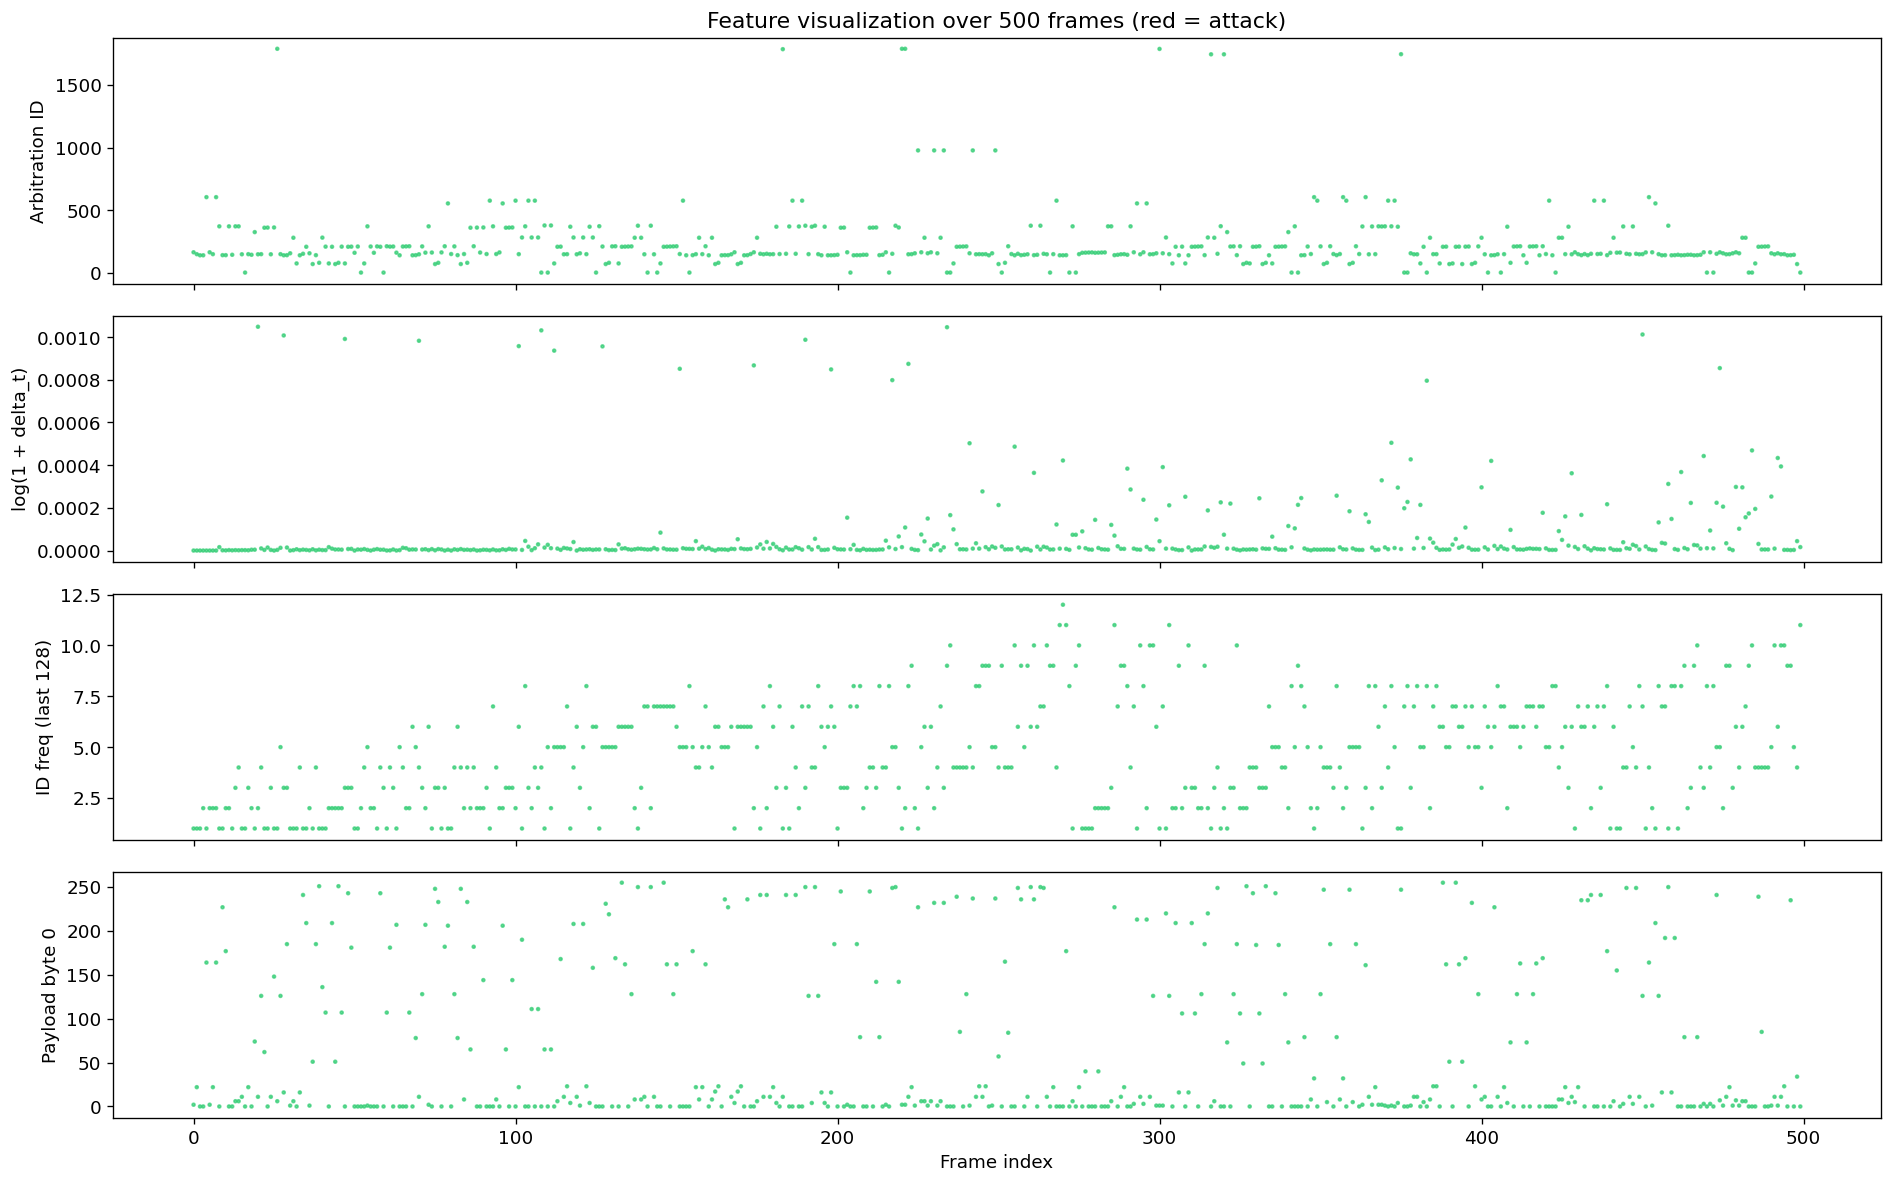

In [9]:
# Visualize engineered features for first 500 frames
N_VIS = 500
fig, axes = plt.subplots(4, 1, figsize=(16, 10), sharex=True)

x = range(N_VIS)
atk_mask = df['attack'].values[:N_VIS] == 1

# 1) Arbitration ID
ax = axes[0]
ax.scatter(x, df['arbitration_id'].values[:N_VIS], c=['#e74c3c' if a else '#2ecc71' for a in atk_mask],
           s=3, alpha=0.7)
ax.set_ylabel('Arbitration ID')
ax.set_title('Feature visualization over 500 frames (red = attack)')

# 2) Delta T
ax = axes[1]
ax.scatter(x, df['log_delta_t'].values[:N_VIS], c=['#e74c3c' if a else '#2ecc71' for a in atk_mask],
           s=3, alpha=0.7)
ax.set_ylabel('log(1 + delta_t)')

# 3) ID frequency
ax = axes[2]
ax.scatter(x, df['id_freq_recent'].values[:N_VIS], c=['#e74c3c' if a else '#2ecc71' for a in atk_mask],
           s=3, alpha=0.7)
ax.set_ylabel('ID freq (last 128)')

# 4) Payload byte 0
ax = axes[3]
ax.scatter(x, df['payload_0'].values[:N_VIS], c=['#e74c3c' if a else '#2ecc71' for a in atk_mask],
           s=3, alpha=0.7)
ax.set_ylabel('Payload byte 0')
ax.set_xlabel('Frame index')

plt.tight_layout()
plt.show()

## Step 4: Normalization

Scale all features to [0, 1] range:
- `arbitration_id`: MinMaxScaler (maps unique IDs to 0-1)
- `dlc`: MinMaxScaler
- `payload_0..7`: divide by 255 (already 0-255 range)
- `log_delta_t`: MinMaxScaler
- `id_freq_recent`: MinMaxScaler

Normalized feature matrix: (5806825, 12)
Value range: [0.0000, 1.0000]


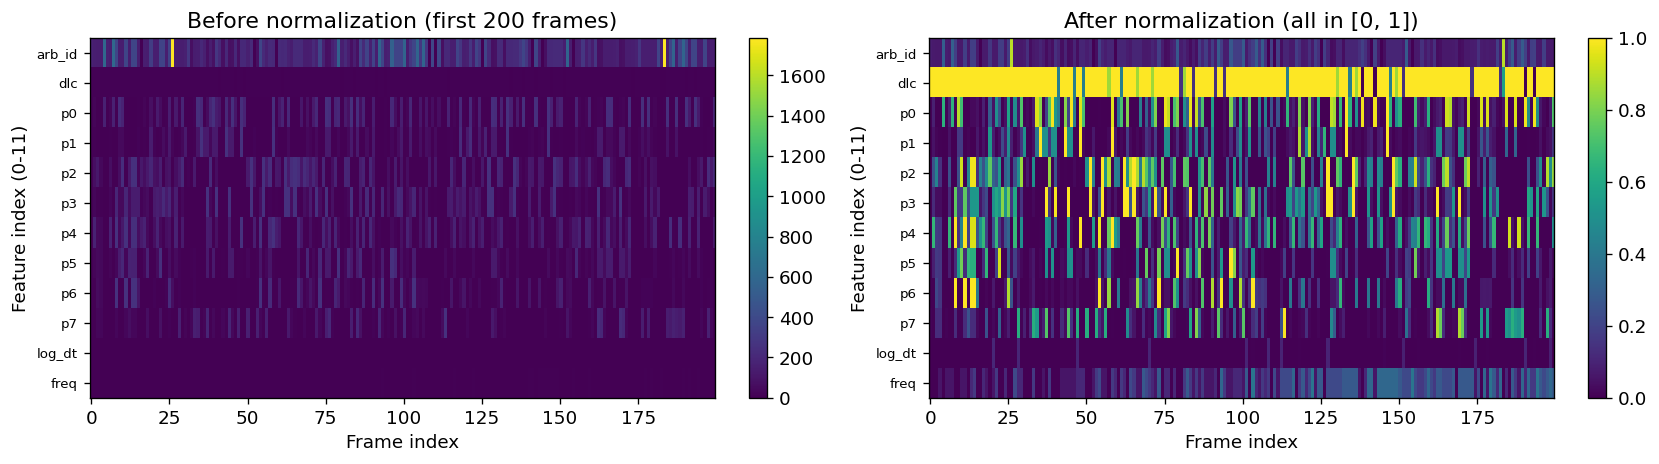

In [10]:
from sklearn.preprocessing import MinMaxScaler

# Fit scalers
scalers = {
    'arbitration_id': MinMaxScaler().fit(df[['arbitration_id']].values.astype(np.float32)),
    'dlc': MinMaxScaler().fit(df[['dlc']].values.astype(np.float32)),
    'log_delta_t': MinMaxScaler().fit(df[['log_delta_t']].values.astype(np.float32)),
    'id_freq_recent': MinMaxScaler().fit(df[['id_freq_recent']].values.astype(np.float32)),
}

# Transform
id_norm = scalers['arbitration_id'].transform(df[['arbitration_id']].values.astype(np.float32))
dlc_norm = scalers['dlc'].transform(df[['dlc']].values.astype(np.float32))
payload_norm = df[[f'payload_{j}' for j in range(8)]].values.astype(np.float32) / 255.0
log_dt_norm = scalers['log_delta_t'].transform(df[['log_delta_t']].values.astype(np.float32))
freq_norm = scalers['id_freq_recent'].transform(df[['id_freq_recent']].values.astype(np.float32))

features = np.concatenate([id_norm, dlc_norm, payload_norm, log_dt_norm, freq_norm], axis=1)
print(f'Normalized feature matrix: {features.shape}')
print(f'Value range: [{features.min():.4f}, {features.max():.4f}]')

# Before vs After normalization
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Before
before = df[feature_cols].values[:200]
im0 = axes[0].imshow(before.T, aspect='auto', cmap='viridis')
axes[0].set_title('Before normalization (first 200 frames)')
axes[0].set_ylabel('Feature index (0-11)')
axes[0].set_xlabel('Frame index')
axes[0].set_yticks(range(12))
axes[0].set_yticklabels(['arb_id', 'dlc', 'p0', 'p1', 'p2', 'p3', 'p4', 'p5', 'p6', 'p7', 'log_dt', 'freq'],
                        fontsize=8)
plt.colorbar(im0, ax=axes[0], fraction=0.046)

# After
im1 = axes[1].imshow(features[:200].T, aspect='auto', cmap='viridis', vmin=0, vmax=1)
axes[1].set_title('After normalization (all in [0, 1])')
axes[1].set_ylabel('Feature index (0-11)')
axes[1].set_xlabel('Frame index')
axes[1].set_yticks(range(12))
axes[1].set_yticklabels(['arb_id', 'dlc', 'p0', 'p1', 'p2', 'p3', 'p4', 'p5', 'p6', 'p7', 'log_dt', 'freq'],
                        fontsize=8)
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

## Step 5: Sliding Window

Convert the long sequence of frames into fixed-length windows:
- **Window size** = 64 frames
- **Stride** = 32 frames (50% overlap)

Each window becomes one sample: shape `(64, 12)` = 64 timesteps x 12 features.

This is what ModernTCN receives as input.

Total frames: 5,806,825
Window size: 64, Stride: 32
Number of windows: 181,462
Each window shape: (64, 12)
First attack frame at index: 1266815
Showing frames 1266735 to 1266985 (region with normal -> attack transition)


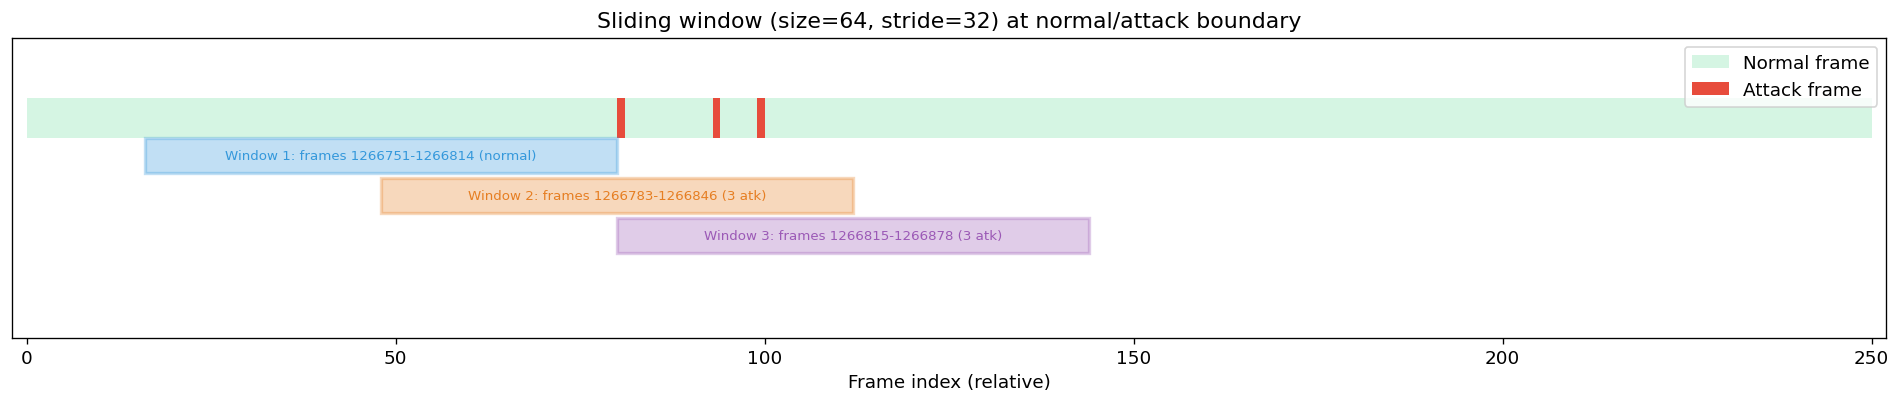

In [11]:
WINDOW_SIZE = 64
STRIDE = 32

attack_bin = df['attack'].values.astype(np.int64)
n_frames = len(features)
n_windows = (n_frames - WINDOW_SIZE) // STRIDE + 1

print(f'Total frames: {n_frames:,}')
print(f'Window size: {WINDOW_SIZE}, Stride: {STRIDE}')
print(f'Number of windows: {n_windows:,}')
print(f'Each window shape: ({WINDOW_SIZE}, 12)')

# Find a region where attack frames start (transition from normal to attack)
# so we can see both green and red in the visualization
atk_indices = np.where(attack_bin == 1)[0]
if len(atk_indices) > 0:
    # Start 80 frames before the first attack so we see the transition
    vis_start = max(0, atk_indices[0] - 80)
else:
    vis_start = 0

N_SHOW = 250
vis_end = min(vis_start + N_SHOW, len(attack_bin))

print(f'First attack frame at index: {atk_indices[0] if len(atk_indices) > 0 else "N/A"}')
print(f'Showing frames {vis_start} to {vis_end} (region with normal -> attack transition)')

# Visualize sliding window concept
fig, ax = plt.subplots(figsize=(16, 3.5))

# Show frame timeline
for i in range(vis_start, vis_end):
    color = '#e74c3c' if attack_bin[i] == 1 else '#d5f5e3'
    ax.barh(0, 1, left=i - vis_start, height=0.4, color=color, edgecolor='none')

# Show 3 overlapping windows positioned around the attack transition
# Window 1: mostly normal, Window 2: transition, Window 3: mostly attack
if len(atk_indices) > 0:
    w1_start_abs = max(vis_start, atk_indices[0] - WINDOW_SIZE)  # before attack
    w2_start_abs = max(vis_start, atk_indices[0] - WINDOW_SIZE // 2)  # straddles
    w3_start_abs = max(vis_start, atk_indices[0])  # starts at attack
    window_starts = [w1_start_abs, w2_start_abs, w3_start_abs]
else:
    window_starts = [vis_start, vis_start + STRIDE, vis_start + 2 * STRIDE]

colors_w = ['#3498db', '#e67e22', '#9b59b6']
labels_w = []
for w_idx, ws_abs in enumerate(window_starts):
    ws_rel = ws_abs - vis_start
    we_abs = ws_abs + WINDOW_SIZE
    n_atk = np.sum(attack_bin[ws_abs:we_abs] == 1) if we_abs <= len(attack_bin) else 0
    lbl = f'Window {w_idx+1}: frames {ws_abs}-{we_abs-1}'
    if n_atk > 0:
        lbl += f' ({n_atk} atk)'
    else:
        lbl += ' (normal)'
    labels_w.append(lbl)

    ax.add_patch(mpatches.Rectangle(
        (ws_rel, -0.55 - w_idx * 0.4), WINDOW_SIZE, 0.35,
        linewidth=2, edgecolor=colors_w[w_idx], facecolor=colors_w[w_idx], alpha=0.3,
    ))
    ax.text(ws_rel + WINDOW_SIZE / 2, -0.55 - w_idx * 0.4 + 0.17,
            lbl, ha='center', va='center', fontsize=8, color=colors_w[w_idx])

ax.set_xlim(-2, N_SHOW + 2)
ax.set_ylim(-2.2, 0.8)
ax.set_xlabel('Frame index (relative)')
ax.set_title(f'Sliding window (size={WINDOW_SIZE}, stride={STRIDE}) at normal/attack boundary')
ax.set_yticks([])

legend_elements = [
    mpatches.Patch(facecolor='#d5f5e3', label='Normal frame'),
    mpatches.Patch(facecolor='#e74c3c', label='Attack frame'),
]
ax.legend(handles=legend_elements, loc='upper right')
plt.tight_layout()
plt.show()

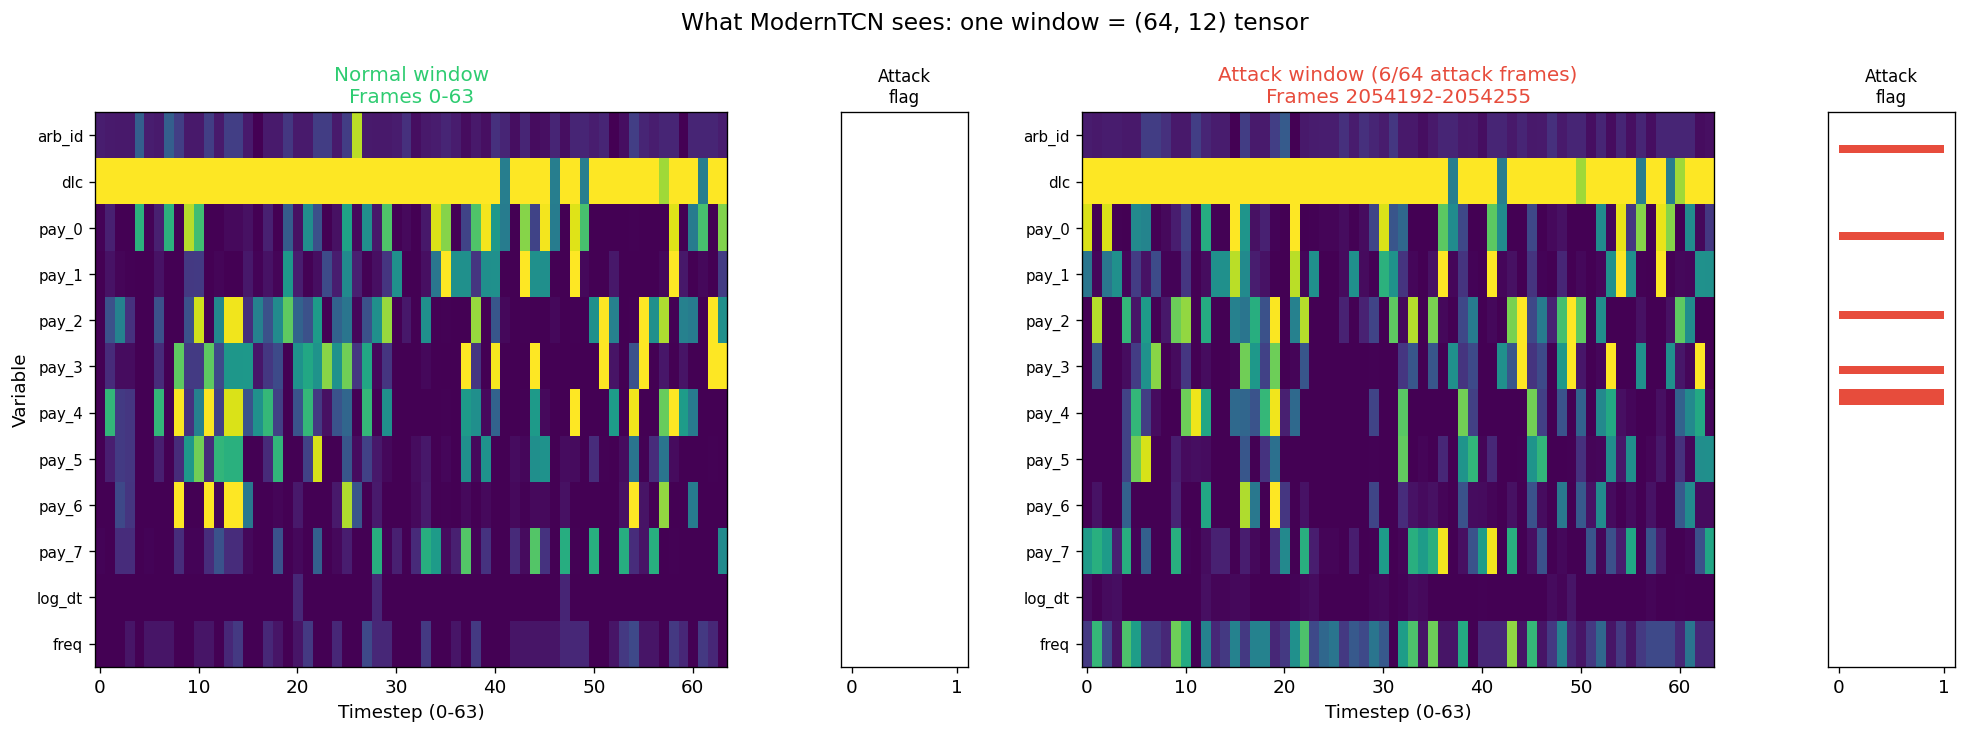


ModernTCN input format:
  Dataloader outputs: (B, T=64, C=12)
  Model permutes to: (B, M=12, L=64)
  M=12 variables, each with L=64 timesteps

Visual differences between normal vs attack:
  Look at arb_id row: attack may show constant ID (DoS) or random jumps (fuzzing)
  Look at log_dt row: attack may show very small values (high-speed flood)
  Look at freq row: attack may show abnormal frequency patterns


In [12]:
# Show TWO windows side by side: one Normal, one Attack
# Find a pure normal window and a pure attack window
normal_start = 0  # fallback
attack_start = 0

# Search for a fully-normal window
for s in range(0, len(features) - WINDOW_SIZE, STRIDE):
    if np.sum(attack_bin[s:s+WINDOW_SIZE]) == 0:
        normal_start = s
        break

# Search for a fully-attack window (all frames are attack)
for s in range(0, len(features) - WINDOW_SIZE, STRIDE):
    if np.sum(attack_bin[s:s+WINDOW_SIZE]) == WINDOW_SIZE:
        attack_start = s
        break
else:
    # Fallback: find window with most attack frames
    if len(atk_indices) > 0:
        attack_start = max(0, atk_indices[len(atk_indices)//2] - WINDOW_SIZE//2)

feat_labels = ['arb_id', 'dlc', 'pay_0', 'pay_1', 'pay_2', 'pay_3',
               'pay_4', 'pay_5', 'pay_6', 'pay_7', 'log_dt', 'freq']

fig, axes = plt.subplots(1, 4, figsize=(20, 6),
                         gridspec_kw={'width_ratios': [3, 0.6, 3, 0.6], 'wspace': 0.3})

# --- Normal window ---
w_norm = features[normal_start:normal_start + WINDOW_SIZE]
a_norm = attack_bin[normal_start:normal_start + WINDOW_SIZE]

im0 = axes[0].imshow(w_norm.T, aspect='auto', cmap='viridis', vmin=0, vmax=1)
axes[0].set_title(f'Normal window\nFrames {normal_start}-{normal_start+WINDOW_SIZE-1}',
                  fontsize=12, color='#2ecc71')
axes[0].set_xlabel('Timestep (0-63)')
axes[0].set_ylabel('Variable')
axes[0].set_yticks(range(12))
axes[0].set_yticklabels(feat_labels, fontsize=9)

axes[1].barh(range(WINDOW_SIZE), a_norm,
             color=['#e74c3c' if a else '#2ecc71' for a in a_norm], height=1.0)
axes[1].set_title('Attack\nflag', fontsize=10)
axes[1].set_xlim(-0.1, 1.1)
axes[1].set_xticks([0, 1])
axes[1].invert_yaxis()
axes[1].set_yticks([])

# --- Attack window ---
w_atk = features[attack_start:attack_start + WINDOW_SIZE]
a_atk = attack_bin[attack_start:attack_start + WINDOW_SIZE]
n_atk_frames = int(np.sum(a_atk))

im1 = axes[2].imshow(w_atk.T, aspect='auto', cmap='viridis', vmin=0, vmax=1)
axes[2].set_title(f'Attack window ({n_atk_frames}/{WINDOW_SIZE} attack frames)\n'
                  f'Frames {attack_start}-{attack_start+WINDOW_SIZE-1}',
                  fontsize=12, color='#e74c3c')
axes[2].set_xlabel('Timestep (0-63)')
axes[2].set_yticks(range(12))
axes[2].set_yticklabels(feat_labels, fontsize=9)

axes[3].barh(range(WINDOW_SIZE), a_atk,
             color=['#e74c3c' if a else '#2ecc71' for a in a_atk], height=1.0)
axes[3].set_title('Attack\nflag', fontsize=10)
axes[3].set_xlim(-0.1, 1.1)
axes[3].set_xticks([0, 1])
axes[3].invert_yaxis()
axes[3].set_yticks([])

plt.suptitle(f'What ModernTCN sees: one window = ({WINDOW_SIZE}, 12) tensor',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print(f'\nModernTCN input format:')
print(f'  Dataloader outputs: (B, T={WINDOW_SIZE}, C=12)')
print(f'  Model permutes to: (B, M=12, L={WINDOW_SIZE})')
print(f'  M=12 variables, each with L={WINDOW_SIZE} timesteps')
print(f'\nVisual differences between normal vs attack:')
print(f'  Look at arb_id row: attack may show constant ID (DoS) or random jumps (fuzzing)')
print(f'  Look at log_dt row: attack may show very small values (high-speed flood)')
print(f'  Look at freq row: attack may show abnormal frequency patterns')

## Step 6: Label Assignment

Each window gets **one label** (sequence-level classification):
- `label_rule = "any_attack"`: if ANY frame in the window is attack → window label = attack class
- Class 0 = normal (all frames are normal)
- Class 1-9 = attack types (from different CSV files)

Windows: X=(181462, 64, 12), y=(181462,)


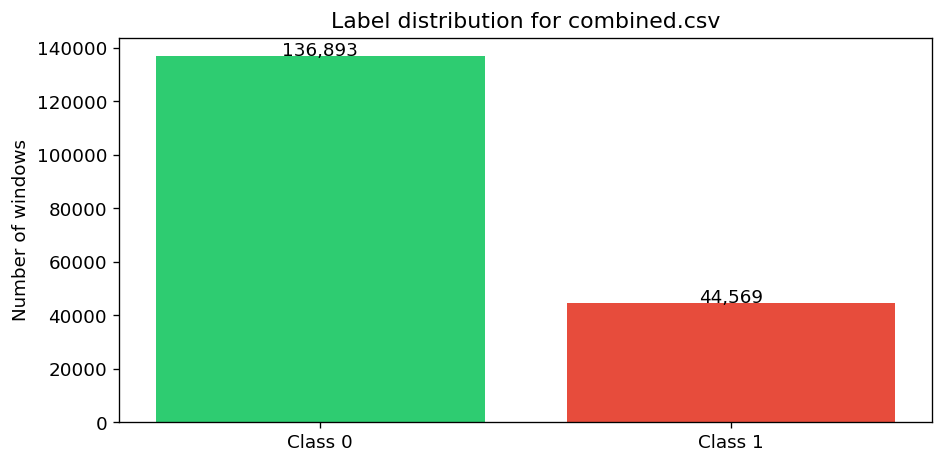

In [13]:
# Create windows and labels
CLASS_ID = 1  # this file's attack class

windows_X, windows_y = [], []
for start in range(0, n_frames - WINDOW_SIZE + 1, STRIDE):
    end = start + WINDOW_SIZE
    xw = features[start:end]
    aw = attack_bin[start:end]
    label = CLASS_ID if np.any(aw == 1) else 0
    windows_X.append(xw)
    windows_y.append(label)

windows_X = np.stack(windows_X)  # (N, 64, 12)
windows_y = np.array(windows_y)  # (N,)

print(f'Windows: X={windows_X.shape}, y={windows_y.shape}')

# Label distribution
vals, cnts = np.unique(windows_y, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar([f'Class {v}' for v in vals], cnts, color=['#2ecc71', '#e74c3c'])
ax.set_title(f'Label distribution for {sample_file.name}')
ax.set_ylabel('Number of windows')
for bar, cnt in zip(bars, cnts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            f'{cnt:,}', ha='center')
plt.tight_layout()
plt.show()

## Step 7: Multi-file Aggregation & Train/Val/Test Split

In the full pipeline:
1. Process ALL CSV files (each with different attack type)
2. Concatenate all windows
3. Stratified split: 70% train, 10% val, 20% test
4. Optional: undersample normal class in training set

In [14]:
# Load the actual preprocessed data (if available)
PREPROCESSED_DIR = Path('../data/2017-subaru-forester/preprocessed')
import torch

if (PREPROCESSED_DIR / 'train.pt').exists():
    train_data = torch.load(PREPROCESSED_DIR / 'train.pt', weights_only=False)
    val_data = torch.load(PREPROCESSED_DIR / 'val.pt', weights_only=False)
    test_data = torch.load(PREPROCESSED_DIR / 'test.pt', weights_only=False)

    X_tr, y_tr = train_data['X'], train_data['y']
    X_val, y_val = val_data['X'], val_data['y']
    X_test, y_test = test_data['X'], test_data['y']

    print(f'Train: X={tuple(X_tr.shape)}, y={tuple(y_tr.shape)}')
    print(f'Val:   X={tuple(X_val.shape)}, y={tuple(y_val.shape)}')
    print(f'Test:  X={tuple(X_test.shape)}, y={tuple(y_test.shape)}')

    # Load metadata
    import json
    meta = json.loads((PREPROCESSED_DIR / 'metadata.json').read_text())
    class_map = meta.get('class_map', {})
    class_names = ['normal'] + [Path(k).stem for k, v in sorted(class_map.items(), key=lambda x: int(x[1]))]
    num_classes = len(class_names)
    print(f'\nClasses ({num_classes}): {class_names}')
else:
    print('Preprocessed data not found. Run preprocess_can_ml_subset.py first.')
    X_tr = y_tr = X_val = y_val = X_test = y_test = None
    class_names = None
    num_classes = 0

Train: X=(492204, 64, 12), y=(492204,)
Val:   X=(87362, 64, 12), y=(87362,)
Test:  X=(174725, 64, 12), y=(174725,)

Classes (10): ['normal', 'combined', 'dos', 'fuzzing', 'gear', 'interval', 'rpm', 'speed', 'standstill', 'systematic']


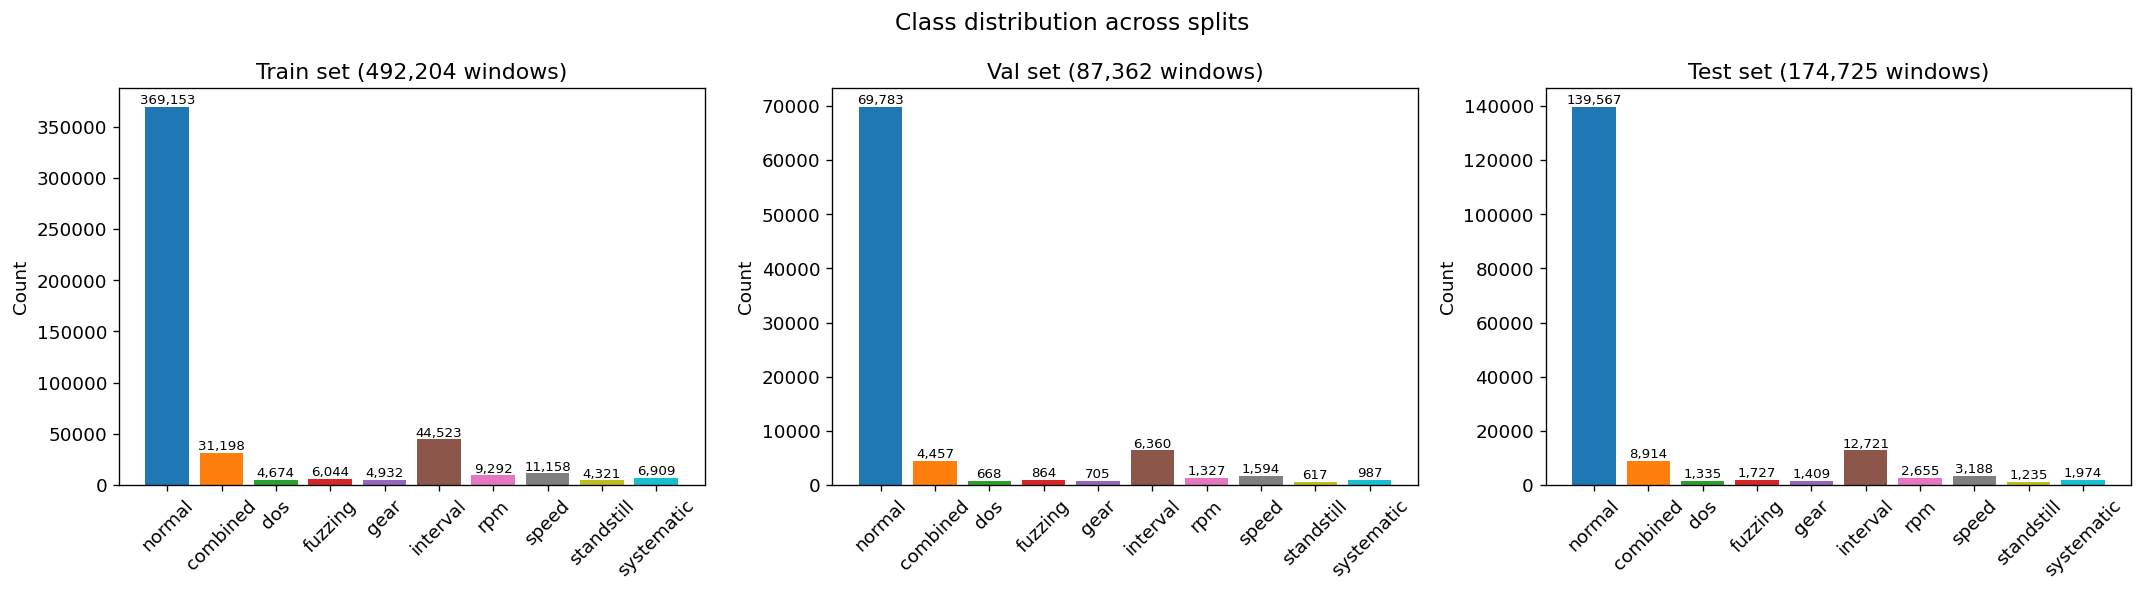

In [15]:
if y_tr is not None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, y, name in zip(axes, [y_tr, y_val, y_test], ['Train', 'Val', 'Test']):
        vals, cnts = np.unique(y.numpy(), return_counts=True)
        colors = plt.cm.tab10(np.linspace(0, 1, num_classes))
        bars = ax.bar([class_names[v] for v in vals], cnts, color=[colors[v] for v in vals])
        ax.set_title(f'{name} set ({len(y):,} windows)')
        ax.set_ylabel('Count')
        ax.tick_params(axis='x', rotation=45)
        for bar, cnt in zip(bars, cnts):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f'{cnt:,}', ha='center', va='bottom', fontsize=8)

    plt.suptitle('Class distribution across splits', fontsize=14)
    plt.tight_layout()
    plt.show()

## Step 8: Final Tensor Format for ModernTCN

The final data format:
- **Input X**: `(B, T=64, C=12)` → model permutes to `(B, M=12, L=64)`
- **Label y**: `(B,)` integer class indices

ModernTCN treats:
- **M=12** as **variables** (arb_id, dlc, 8 payload bytes, log_delta_t, id_freq)
- **L=64** as **temporal dimension** (64 consecutive CAN frames)
- Each variable is independently patched, then processed through DWConv → ConvFFN

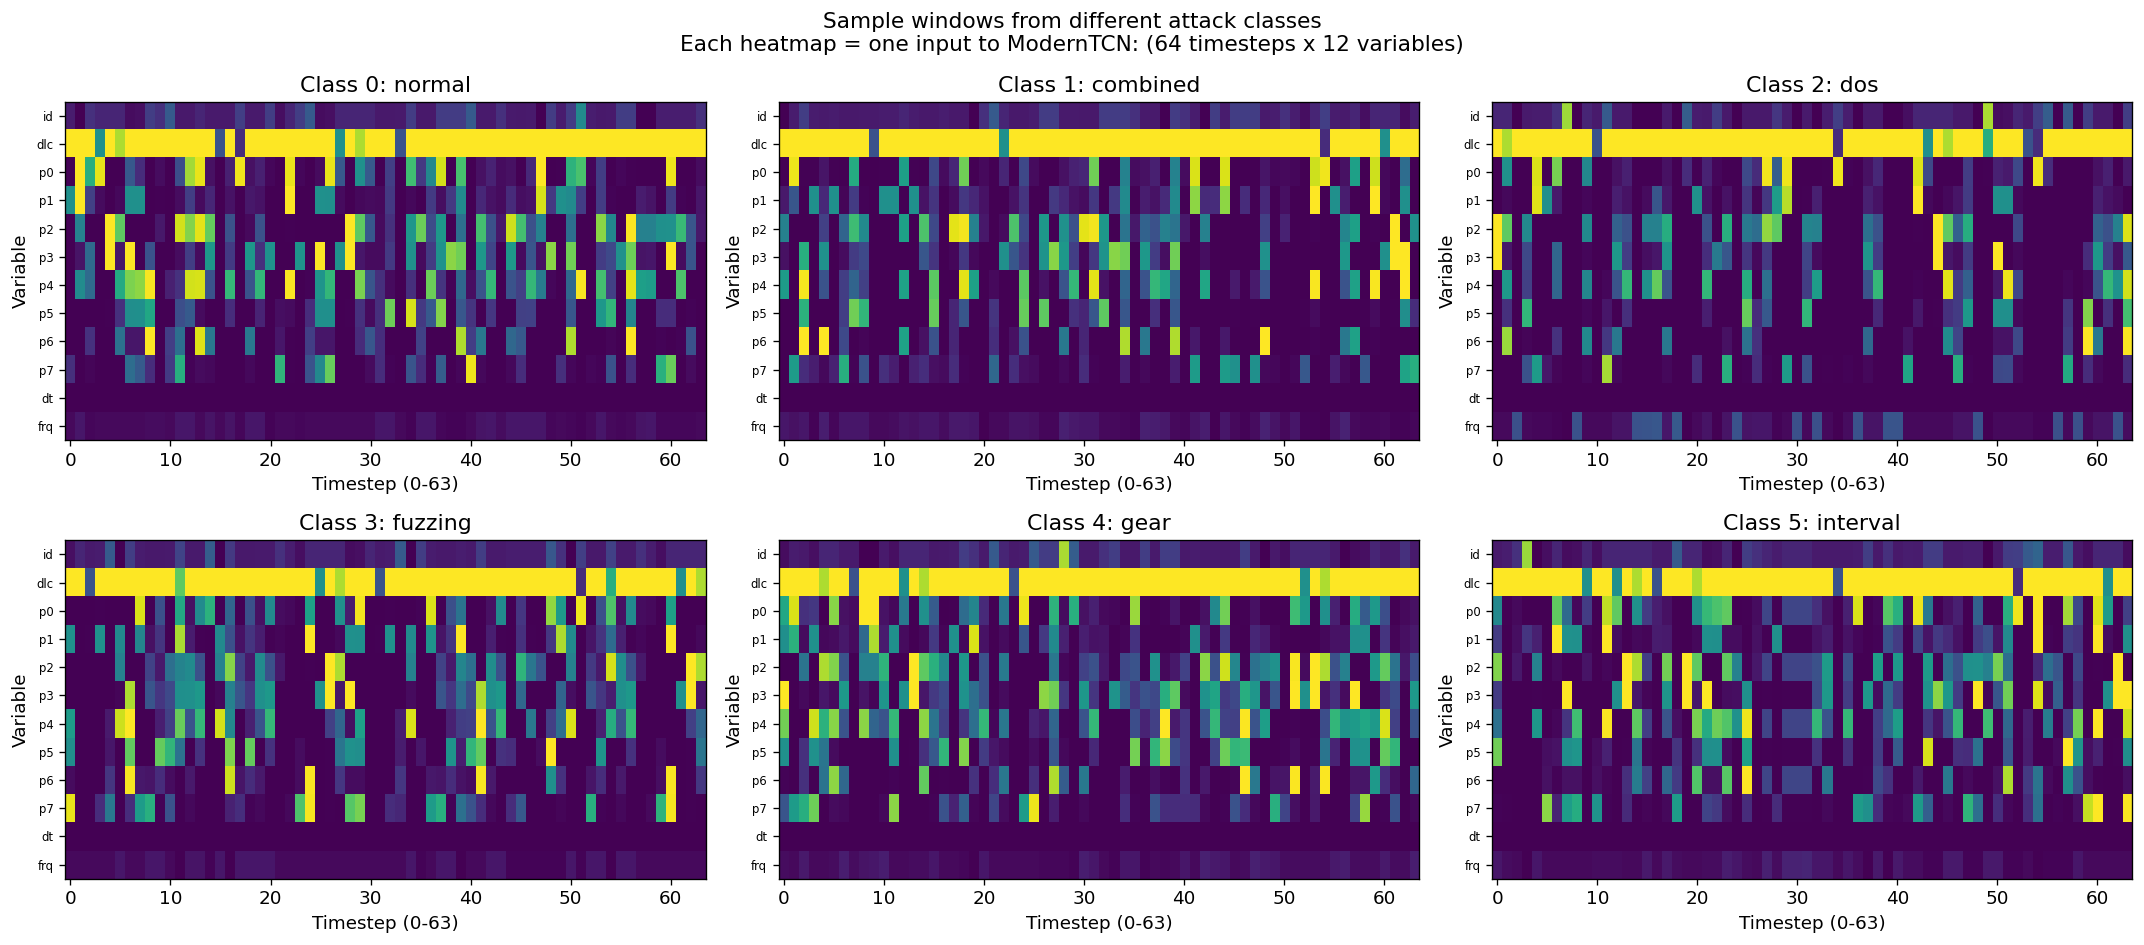

In [16]:
if X_tr is not None:
    # Show samples from different classes
    fig, axes = plt.subplots(2, 3, figsize=(18, 8))

    shown_classes = []
    for cls_id in range(min(6, num_classes)):
        idx = (y_tr == cls_id).nonzero(as_tuple=True)[0]
        if len(idx) == 0:
            continue
        sample = X_tr[idx[0]].numpy()  # (64, 12)
        ax = axes[cls_id // 3, cls_id % 3]
        im = ax.imshow(sample.T, aspect='auto', cmap='viridis', vmin=0, vmax=1)
        ax.set_title(f'Class {cls_id}: {class_names[cls_id]}')
        ax.set_xlabel('Timestep (0-63)')
        ax.set_ylabel('Variable')
        ax.set_yticks(range(12))
        ax.set_yticklabels(['id', 'dlc', 'p0', 'p1', 'p2', 'p3',
                            'p4', 'p5', 'p6', 'p7', 'dt', 'frq'], fontsize=7)

    plt.suptitle('Sample windows from different attack classes\n'
                 'Each heatmap = one input to ModernTCN: (64 timesteps x 12 variables)',
                 fontsize=13)
    plt.tight_layout()
    plt.show()

In [17]:
if X_tr is not None:
    # Summary statistics
    print('=' * 60)
    print('PREPROCESSING SUMMARY')
    print('=' * 60)
    print(f'\nDataset: 2017-subaru-forester (CAN-ML)')
    print(f'Source files: {len(csv_files)} CSV files (9 attack types + normal)')
    print(f'\nFeature engineering:')
    print(f'  Raw columns: timestamp, arbitration_id, data_field, attack')
    print(f'  Engineered: 12 features per frame')
    print(f'  Normalization: MinMaxScaler + /255 for payload')
    print(f'\nWindowing:')
    print(f'  Window size: {WINDOW_SIZE} frames')
    print(f'  Stride: {STRIDE} frames')
    print(f'  Label rule: any_attack')
    print(f'\nFinal tensor shapes:')
    print(f'  Train: X={tuple(X_tr.shape)}, y={tuple(y_tr.shape)}')
    print(f'  Val:   X={tuple(X_val.shape)}, y={tuple(y_val.shape)}')
    print(f'  Test:  X={tuple(X_test.shape)}, y={tuple(y_test.shape)}')
    print(f'  Num classes: {num_classes}')
    print(f'\nModernTCN input interpretation:')
    print(f'  (B, T=64, C=12) -> permute -> (B, M=12, L=64)')
    print(f'  M=12 variables (independent channels for DWConv)')
    print(f'  L=64 timesteps (temporal axis for convolution)')

PREPROCESSING SUMMARY

Dataset: 2017-subaru-forester (CAN-ML)
Source files: 9 CSV files (9 attack types + normal)

Feature engineering:
  Raw columns: timestamp, arbitration_id, data_field, attack
  Engineered: 12 features per frame
  Normalization: MinMaxScaler + /255 for payload

Windowing:
  Window size: 64 frames
  Stride: 32 frames
  Label rule: any_attack

Final tensor shapes:
  Train: X=(492204, 64, 12), y=(492204,)
  Val:   X=(87362, 64, 12), y=(87362,)
  Test:  X=(174725, 64, 12), y=(174725,)
  Num classes: 10

ModernTCN input interpretation:
  (B, T=64, C=12) -> permute -> (B, M=12, L=64)
  M=12 variables (independent channels for DWConv)
  L=64 timesteps (temporal axis for convolution)
